[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pantrok/hidroxai-mx/blob/main/notebooks/tutoriales/05_alertas_difusas.ipynb)

# Tutorial 5 · Alertas difusas

**Objetivo.** convertir un ensamble de pronósticos en niveles de alerta con el sistema Mamdani del benchmark (percentil y dispersión), compararlo con un umbral simple mediante POD, FAR y CSI, y ver la línea de tiempo de alertas de una estación.

> Las cifras son ilustrativas: el ensamble del tutorial tiene 4 miembros (2 modelos × 2 semillas) y el del benchmark 12. Los resultados del benchmark están en [`results/xai_benchmark/`](https://github.com/pantrok/hidroxai-mx/tree/xai-benchmark-v1.5/results/xai_benchmark) (archivos `rq3_*`).

*Proyecto IND-2026-0335 · Instituto Politécnico Nacional (IPN) · Convocatoria PICDT2026. Datos: CONAGUA (Sistema de Información Hidrológica), INEGI y HydroSHEDS.*

In [1]:
# En Colab instala la biblioteca desde GitHub; fuera de Colab usa la que ya esté instalada.
# Va sin dependencias porque Colab ya trae pandas, pyarrow, matplotlib, torch y xgboost.
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules and importlib.util.find_spec("hidroxai_mx") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                    "git+https://github.com/pantrok/hidroxai-mx@main"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "captum"], check=True)

## 1. Ensamble de pronósticos

`E.entrenar` repite los pasos del tutorial 3: XGBoost y TCN con dos semillas, horizonte de 1 día, en Alta del Balsas.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hidroxai_mx import ejemplos as E
from hidroxai_mx.alert import evaluation as AE
from hidroxai_mx.alert import fuzzy as F
from hidroxai_mx.dataset import abrir_dataset, como_citar

REDUCIDO = E.modo_reducido()           # modo rápido para la integración continua
ds = abrir_dataset()
claves = E.claves_cuenca(ds.vinculo_hidrorivers(), E.CUENCA)
if REDUCIDO:
    claves = claves[:3]
paneles = E.paneles(ds.tabla_caracteristicas(claves=claves), claves)
res = E.entrenar(paneles, h=1)
meta = res["arr"]["test"]["meta"]
miembros = np.stack([res["pronosticos"][k] for k in sorted(res["pronosticos"])])   # [4, n] en m³/s
print(f"{len(paneles)} estaciones; ensamble de {len(miembros)} miembros; {miembros.shape[1]:,} pronósticos")

12 estaciones; ensamble de 4 miembros; 6,710 pronósticos


## 2. El sistema Mamdani

Dos entradas por pronóstico:

- **percentil:** el de la media del ensamble en la distribución del gasto observado de la estación en el periodo de entrenamiento;
- **dispersión:** el rango intercuartílico de los percentiles de los miembros.

La salida es un nivel: normal, vigilancia, alerta o emergencia. Las funciones de pertenencia y las 8 reglas son las congeladas en el protocolo del benchmark.

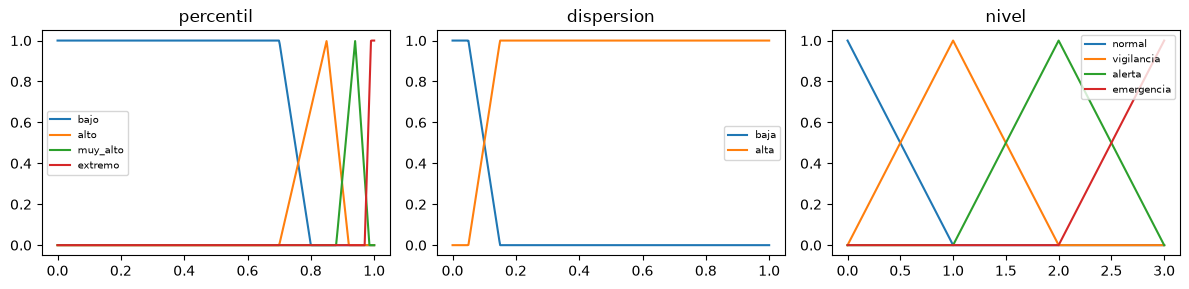

,percentil,dispersion,nivel
0,bajo,baja,normal
1,bajo,alta,normal
2,alto,baja,vigilancia
3,alto,alta,vigilancia
4,muy_alto,baja,alerta
5,muy_alto,alta,vigilancia
6,extremo,baja,emergencia
7,extremo,alta,alerta


In [3]:
fis = F.build_protocol_fis()
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, var in zip(axes, [fis.inputs["percentil"], fis.inputs["dispersion"], fis.output]):
    u = np.linspace(var.universe_min, var.universe_max, 400)
    for nombre, mf in var.mfs.items():
        ax.plot(u, mf(u), label=nombre)
    ax.set_title(var.name)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
fis.rules_table()

In [4]:
NIVELES = ["normal", "vigilancia", "alerta", "emergencia"]
lv = AE.ensemble_levels(fis, miembros, meta, E.observaciones_entrenamiento(paneles))
pd.Series(lv["nivel"]).map(dict(enumerate(NIVELES))).value_counts().reindex(NIVELES).fillna(0).astype(int)

normal        4468
vigilancia    1566
alerta         669
emergencia       7
Name: count, dtype: int64

## 3. Difuso contra umbral

Un **evento** es un gasto observado mayor que el percentil 90 (P90) o 99 (P99) del entrenamiento de la estación. El sistema difuso alerta un evento P90 con nivel **alerta** o mayor y un P99 con **emergencia**; el umbral simple alerta cuando el percentil de la media del ensamble pasa de 0.90 o 0.99.

POD = aciertos / eventos; FAR = falsas alarmas / alertas; CSI = aciertos / (aciertos + fallos + falsas alarmas).

In [5]:
filas = AE.contingency(lv, meta, evaluable=set(meta["clave"]))
tab = pd.DataFrame(filas).groupby(["evento", "metodo"])[["aciertos", "fallos", "falsas", "negativos"]].sum()
tab.join(tab.apply(lambda r: pd.Series(AE.scores(r)), axis=1)).round(3)

aciertos  fallos  falsas  negativos    pod    far    csi
evento metodo                                                          
P90    difuso       504     334     172       5700  0.601  0.254  0.499
       umbral       482     356     171       5701  0.575  0.262  0.478
P99    difuso         0      71       7       6632  0.000  1.000  0.000
       umbral         0      71       3       6636  0.000  1.000  0.000

## 4. Línea de tiempo de una estación

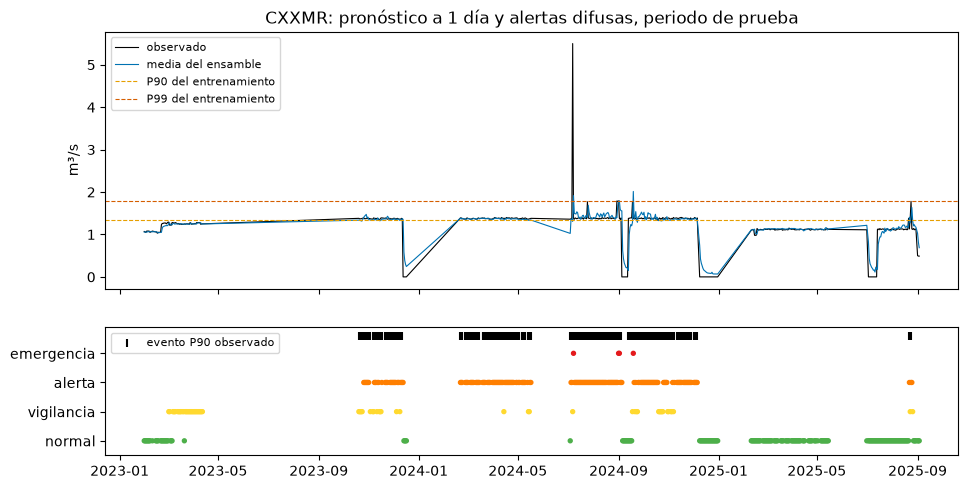

In [6]:
eventos = meta["y_flow"].to_numpy() > lv["umbral"]["P90"]
clave = pd.Series(eventos).groupby(meta["clave"].to_numpy()).sum().idxmax()
s = (meta["clave"] == clave).to_numpy()
fechas = meta.loc[s, "target_date"].to_numpy()
COLORES = ["#4DAF4A", "#FFD92F", "#FF7F00", "#E41A1C"]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(fechas, meta.loc[s, "y_flow"], color="k", lw=0.8, label="observado")
a1.plot(fechas, lv["ensamble"][s], color="#0072B2", lw=0.8, label="media del ensamble")
for e, color in (("P90", "#E69F00"), ("P99", "#D55E00")):
    a1.axhline(lv["umbral"][e][s][0], color=color, ls="--", lw=0.8, label=f"{e} del entrenamiento")
a1.set_ylabel("m³/s")
a1.set_title(f"{clave}: pronóstico a 1 día y alertas difusas, periodo de prueba")
a1.legend(fontsize=8, loc="upper left")
a2.scatter(fechas, lv["nivel"][s], c=[COLORES[n] for n in lv["nivel"][s]], s=8)
a2.scatter(fechas[eventos[s]], np.full(eventos[s].sum(), 3.6), marker="|", color="k", label="evento P90 observado")
a2.set_yticks(range(4), NIVELES)
a2.set_ylim(-0.5, 3.9)
a2.legend(fontsize=8, loc="upper left")
plt.show()

## 5. Comparación con el benchmark

Resultados publicados para la misma cuenca y horizonte (`rq3_summary.csv` del tag `xai-benchmark-v1.5`):

In [7]:
bench = pd.read_csv("https://raw.githubusercontent.com/pantrok/hidroxai-mx/xai-benchmark-v1.5/results/xai_benchmark/rq3_summary.csv")
bench[(bench["grupo"] == E.CUENCA) & (bench["h"] == 1)][
    ["evento", "estaciones", "difuso_pod", "difuso_far", "difuso_csi", "umbral_pod", "umbral_far", "umbral_csi"]
].reset_index(drop=True)

,evento,estaciones,difuso_pod,difuso_far,difuso_csi,umbral_pod,umbral_far,umbral_csi
0,P90,12,0.6002,0.2436,0.503,0.5632,0.2496,0.4744
1,P99,12,0.0000,1.0000,0.000,0.0000,1.0000,0.0000


## Cómo citar

Si usas estos datos, cita la versión del dataset que usaste. El texto sale de los metadatos del depósito en Zenodo.

In [8]:
print(como_citar())

Sánchez-Ruiz, D., Ramos Aguilar, E., Ramos-Aguilar, R., Reyes-Peña, C., Reyes-Cocoletzi, L., & García-Ramírez, J. (2026). Hidro-MX v2026.11: a reproducible hydroclimatic dataset for Mexican pilot basins (CONAGUA-SIH and INEGI) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.24119292
Todas las versiones (DOI de concepto): https://doi.org/10.5281/zenodo.21231600
Créditos: Instituto Politécnico Nacional (IPN) · Convocatoria PICDT2026 · proyecto IND-2026-0335. Datos: CONAGUA (Sistema de Información Hidrológica), INEGI y HydroSHEDS.
